SECT-4451 — Lecture 2 Practical

Data Exploration and Foundational Mathematics
Task: Instead of creating your own data, use the provided dataset. This
data represents student performance, but it contains a "dirty" record and
significant variance in scale.

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

n = 100
study_hours = np.random.normal(5, 2, n)
attendance = np.random.normal(85, 10, n)
previous_mark = np.random.normal(70, 15, n)
final_score = (0.5 * study_hours) + (0.3 * attendance) + (0.2 * previous_mark) + np.random.normal(0, 5, n)
df = pd.DataFrame({
'study_hours': study_hours,
'attendance': attendance,
'previous_mark': previous_mark,
'final_score': final_score
})

df.loc[0:5, 'study_hours'] = np.nan # Missing values
df.loc[99, 'study_hours'] = 50 # Outlier
df.loc[98, 'attendance'] = -10 # Impossible value

print(df)
# df.to_csv('student_data.csv', index=False)



    study_hours  attendance  previous_mark  final_score
0           NaN   70.846293      75.366810    35.178989
1           NaN   80.793547      78.411768    39.481248
2           NaN   81.572855      86.245769    48.605167
3           NaN   76.977227      85.807031    47.329456
4           NaN   83.387143      49.334959    37.044473
..          ...         ...            ...          ...
95     2.072970   88.853174      59.606356    37.267830
96     5.592241   76.161426      83.493998    33.777675
97     5.522111   86.537251      74.609493    50.413491
98     5.010227  -10.000000      82.192932    44.045627
99    50.000000   73.570297      79.444433    46.414470

[100 rows x 4 columns]


Part A — Inspect and Clean
A1. Identify the outlier in study_hours (the student with 50 hours). Remove or
cap this value as you see fit. Justify your choice.

In [16]:
# Count missing values in each column
print("\nMissing values:")
print(df.isnull().sum())

# Inspect the records containing dirty data records
print("\nRecords requiring inspection:")
display(df.loc[[0, 1, 2, 3, 4, 5, 98, 99]])


Missing values:
study_hours      6
attendance       0
previous_mark    0
final_score      0
dtype: int64

Records requiring inspection:


,study_hours,attendance,previous_mark,final_score
0,NaN,70.846293,75.366810,35.178989
1,NaN,80.793547,78.411768,39.481248
2,NaN,81.572855,86.245769,48.605167
3,NaN,76.977227,85.807031,47.329456
4,NaN,83.387143,49.334959,37.044473
5,NaN,89.040509,55.932624,40.751177
98,5.010227,-10.000000,82.192932,44.045627
99,50.000000,73.570297,79.444433,46.414470


The value of 50 in study_hours is an outlier because it is substantially higher than the typical values in the dataset. The initial descriptive statistics show a median of approximately 4.812 hours and a maximum of 50 hours.

I chose to cap the outlier rather than remove the entire student record. To determine an appropriate upper limit, I used the interquartile range (IQR) method. The IQR is the difference between the third quartile (Q3) and the first quartile (Q1):


IQR=Q3-Q1


The upper outlier threshold is calculated as:


Upper bound=Q3+1.5(IQR)


After excluding the known outlier and invalid negative study-hour values, the calculated threshold was approximately 8.663 hours. I capped values above this threshold using the pandas clip() method. Consequently, the value of 50 hours was replaced with approximately 8.663 hours.

### Capping was selected because it limits the influence of an extreme value while preserving the student's record and its other attributes. I also handled invalid negative values and missing observations separately to improve the dataset's quality. The IQR method identifies potential outliers; it does not, by itself, prove that an observation is erroneous. in addition, as seen from the above output there are also missing issues and impossible records.

In [5]:
# Create a separate DataFrame for cleaning
df_clean = df.copy()

# Treat negative study hours as invalid
df_clean.loc[df_clean["study_hours"] < 0, "study_hours"] = np.nan

# Treat negative attendance as invalid
df_clean.loc[df_clean["attendance"] < 0, "attendance"] = np.nan

# Exclude the known outlier of 50 when calculating the IQR threshold
valid_hours = df_clean.loc[
    df_clean["study_hours"].notna()
    & (df_clean["study_hours"] != 50),
    "study_hours"
]

# Calculate the quartiles and IQR
Q1 = valid_hours.quantile(0.25)
Q3 = valid_hours.quantile(0.75)
IQR = Q3 - Q1

# Calculate the upper outlier threshold
upper_bound = Q3 + 1.5 * IQR

print("First quartile (Q1):", round(Q1, 3))
print("Third quartile (Q3):", round(Q3, 3))
print("Interquartile range (IQR):", round(IQR, 3))
print("Upper outlier threshold:", round(upper_bound, 3))

# Cap study-hour values at the upper threshold
df_clean["study_hours"] = df_clean["study_hours"].clip(
    upper=upper_bound
)

# Impute missing study hours using the median
study_median = df_clean["study_hours"].median()
df_clean["study_hours"] = df_clean["study_hours"].fillna(
    study_median
)

# Impute invalid attendance using the median of valid observations
attendance_median = df_clean["attendance"].median()
df_clean["attendance"] = df_clean["attendance"].fillna(
    attendance_median
)

# Check whether missing values remain
print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

# Inspect the affected records after cleaning
print("\nCleaned records:")
display(df_clean.loc[[0, 1, 2, 3, 4, 5, 98, 99]])

First quartile (Q1): 3.775
Third quartile (Q3): 5.73
Interquartile range (IQR): 1.955
Upper outlier threshold: 8.663

Missing values after cleaning:
study_hours      0
attendance       0
previous_mark    0
final_score      0
dtype: int64

Cleaned records:


,study_hours,attendance,previous_mark,final_score
0,4.855980,70.846293,75.366810,35.178989
1,4.855980,80.793547,78.411768,39.481248
2,4.855980,81.572855,86.245769,48.605167
3,4.855980,76.977227,85.807031,47.329456
4,4.855980,83.387143,49.334959,37.044473
5,4.855980,89.040509,55.932624,40.751177
98,5.010227,85.996514,82.192932,44.045627
99,8.663437,73.570297,79.444433,46.414470


A2. What is the shape of the feature matrix? Which columns are numerical? Which
column is your target variable?

In supervised machine learning, the feature matrix X contains the input variables, and the target vector y contains the outcome to be predicted.

For this practical, the three input features are study_hours, attendance, and previous_mark. The target variable is final_score.

The feature matrix should contain 100 rows and three columns, while the target should contain 100 values.

In [6]:
# Select the input features
X = df_clean[
    ["study_hours", "attendance", "previous_mark"]
]

# Select the target variable
y = df_clean["final_score"]

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nFeature data types:")
print(X.dtypes)

print("\nTarget variable: final_score")

Feature matrix shape: (100, 3)
Target vector shape: (100,)

Feature data types:
study_hours      float64
attendance       float64
previous_mark    float64
dtype: object

Target variable: final_score


Part B — Summarize
1. Calculate the mean, median, and standard deviation for all columns.

In [7]:
# Calculate the mean, median, and standard deviation for all columns
summary = pd.DataFrame({
    "Mean": df_clean.mean(),
    "Median": df_clean.median(),
    "Standard Deviation": df_clean.std()
})

display(summary.round(3))

,Mean,Median,Standard Deviation
study_hours,4.834,4.856,1.745
attendance,85.227,85.997,9.537
previous_mark,70.973,71.465,16.264
final_score,42.692,42.763,6.087


2. Write 3 observations in plain English. Example: "The standard deviation of
attendance is low, suggesting that most students maintain a consistent
attendance rate.

a) The standard deviation for study time is low, suggesting that most students spend a similar amount of time studying.
b) The standard deviation for previous mark is high, suggesting that students have different levels of previous academic performance.
c) The standard deviation for final score is relatively low, suggesting that students' final scores are generally closer to the average.

Part C — Visualize
C1. Create a histogram for final_score.

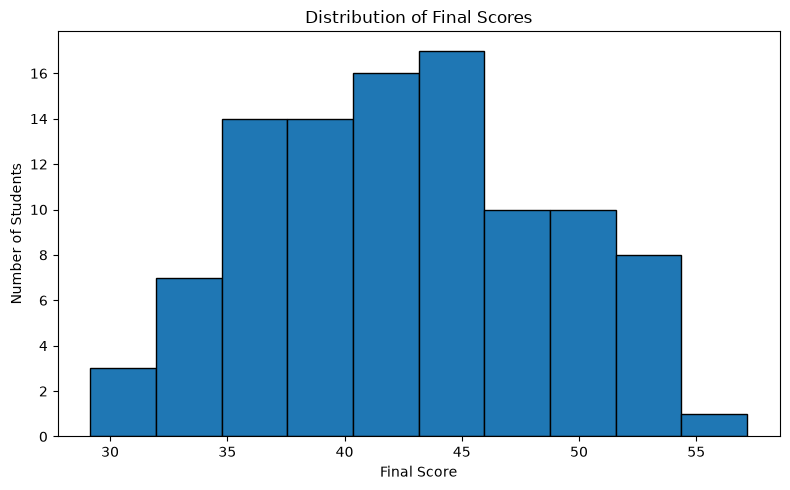

In [10]:
plt.figure(figsize=(8, 5))

plt.hist(
    df_clean["final_score"],
    bins=10,
    edgecolor="black"
)

plt.title("Distribution of Final Scores")
plt.xlabel("Final Score")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

C2. Create a scatter plot of study_hours vs final_score. Describe the trend.

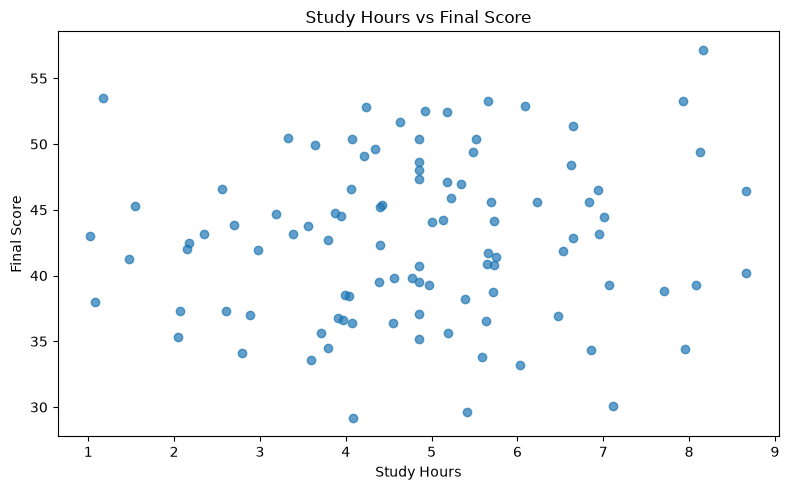

In [11]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df_clean["study_hours"],
    df_clean["final_score"],
    alpha=0.7
)

plt.title("Study Hours vs Final Score")
plt.xlabel("Study Hours")
plt.ylabel("Final Score")
plt.tight_layout()
plt.show()

As study hours increase, final scores tend to increase slightly. However, the points are widely spread, meaning students who study similar amounts can still receive different scores. Therefore, studying more may be associated with higher scores, but study hours alone do not reliably predict a student's final score.

Part D — Correlation and Causality
D1. Calculate the Pearson correlation coefficient between study_hours and
final_score.

In [12]:
# Calculate Pearson correlation using the cleaned study hours
correlation = df_clean["study_hours"].corr(
    df_clean["final_score"],
    method="pearson"
)

print(
    "Pearson correlation between study hours and final score:",
    round(correlation, 3)
)

Pearson correlation between study hours and final score: 0.09


D2. Critical Thinking: If a student studies 10 hours, does the correlation
guarantee they will get a specific score? What is a potential "lurking" or
"confounding" variable that could explain the link between study time and
scores?

r = 0.09

This is very close to zero, so it indicates a very weak positive linear relationship between study hours and final scores in the cleaned dataset. Therefore, the correlation gives us very little evidence of a linear relationship that could help us predict scores from study hours alone.
No. Correlation describes a relationship across observations, it does not guarantee an exact outcome or prove causation.

What is a potential confounding or lurking variable?

A potential confounding variable is students' previous academic performance. Students with stronger prior knowledge may achieve higher final scores regardless of how many hours they study.

Part E — Vectors and Dot Product
1. Select one student row (excluding the target) as a vector \mathbf{x}.
2. Define a weight vector f{w} = [0.5, 0.2, 0.4] and a bias b = 5.
3. Calculate {y} = f{w} dot f{x} + b using NumPy.

A vector is an ordered collection of numerical values. Each student can be represented by a feature vector containing study hours, attendance, and previous marks.

A simple linear model combines the features using a weight vector and adds a bias:

ŷ = w · x + b

Here, x is the student's feature vector, w is the weight vector, and b is the bias. The dot product multiplies corresponding feature and weight values and adds the results together.

For this practical, the required weights are [0.5, 0.2, 0.4], and the bias is 5.

In [13]:
# Select one student and exclude the target variable
student_index = 6

x = df_clean.loc[
    student_index,
    ["study_hours", "attendance", "previous_mark"]
].to_numpy()

# Define the required weight vector and bias
w = np.array([0.5, 0.2, 0.4])
b = 5

# Calculate the dot product and add the bias
prediction = np.dot(w, x) + b

print("Selected student index:", student_index)
print("Feature vector x:", x)
print("Weight vector w:", w)
print("Bias b:", b)
print("Dot product:", np.dot(w, x))
print("Model output:", prediction)

Selected student index: 6
Feature vector x: [  8.15842563 103.86185901  77.72552901]
Weight vector w: [0.5 0.2 0.4]
Bias b: 5
Dot product: 55.94179622118041
Model output: 60.94179622118041


I selected student index 6 and used study hours, attendance, and previous mark as the feature vector. I defined the weight vector as `[0.5, 0.2, 0.4]` and the bias as `5`. Using NumPy's dot product, I obtained approximately 55.942. After adding the bias, the final model output was approximately 60.942.

E4. Conceptually: What does f{w} represent in the context of predicting a
score?

The function f{w} represents the model's calculation for predicting a student's final score using their study hours, attendance, and previous marks. It multiplies each feature by its corresponding weight and adds the results together.

Why do we need b?
The bias is a number that the model adds to its prediction or result  and it gives the model a way to correct that overall offset. In this case the given bias is 5.

Part F — Scaling
F1. Standardize study_hours and previous_mark (use (x -mean) / standard deviation).

In [17]:
df_scaled = df_clean.copy()

# Calculate the mean and standard deviation
study_mean = df_clean["study_hours"].mean()
study_std = df_clean["study_hours"].std()

mark_mean = df_clean["previous_mark"].mean()
mark_std = df_clean["previous_mark"].std()

# Standardize study_hours
df_scaled["study_hours_scaled"] = (
    df_clean["study_hours"] - study_mean
) / study_std

# Standardize previous_mark
df_scaled["previous_mark_scaled"] = (
    df_clean["previous_mark"] - mark_mean
) / mark_std

# Display the results
display(df_scaled[
    ["study_hours", "study_hours_scaled",
     "previous_mark", "previous_mark_scaled"]
].head())

,study_hours,study_hours_scaled,previous_mark,previous_mark_scaled
0,4.85598,0.012417,75.366810,0.270124
1,4.85598,0.012417,78.411768,0.457342
2,4.85598,0.012417,86.245769,0.939012
3,4.85598,0.012417,85.807031,0.912037
4,4.85598,0.012417,49.334959,-1.330433


F2. Why would a distance-based algorithm (like K-Nearest Neighbors) fail if we
didn't scale these two features? (Hint: compare the original range of
study_hours vs previous_mark).


Because previous_mark has a much larger numerical range, differences in marks can contribute much more to the calculated distance than differences in study hours. As a result, K-Nearest Neighbors may give previous marks too much influence and study hours too little influence when deciding which students are closest. Standardization helps by putting both features on a comparable scale, so their numerical ranges do not unfairly favor one feature. We can see the difference the ratio of the originila values and the scaled one.